# 02_alignment_and_eda

## Setup

Set things up and load the DSCOVR data I cached during the audit.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

RAW = Path("../data/raw")
INTERIM = Path("../data/interim")
PROCESSED = Path("../data/processed")

START = pd.Timestamp("2016-07-26 00:00")
END = pd.Timestamp("2026-06-29 23:00")

needed = [
    INTERIM / "dscovr_mag_1min_all.parquet",
    INTERIM / "dscovr_fc_1min_all.parquet",
    RAW / "kp" / "gfz_Kp_ap_Ap_SN_F107_since_1932.txt",
    RAW / "f107" / "celestrak_SW-All.csv",
]
for p in needed:
    print("exists" if p.exists() else "MISSING", p.name)

mag = pd.read_parquet(INTERIM / "dscovr_mag_1min_all.parquet")
fc = pd.read_parquet(INTERIM / "dscovr_fc_1min_all.parquet")

print()
print("mag:", mag.shape, "| time dtype:", mag["time"].dtype, "|", mag["time"].min(), "to", mag["time"].max())
print("fc :", fc.shape, "| time dtype:", fc["time"].dtype, "|", fc["time"].min(), "to", fc["time"].max())
print("expected hours in window:", len(pd.date_range(START, END, freq="h")))

exists dscovr_mag_1min_all.parquet
exists dscovr_fc_1min_all.parquet
exists gfz_Kp_ap_Ap_SN_F107_since_1932.txt
exists celestrak_SW-All.csv

mag: (5148000, 17) | time dtype: datetime64[ms] | 2016-07-26 00:00:00 to 2026-06-29 23:59:00
fc : (5148000, 27) | time dtype: datetime64[ms] | 2016-07-26 00:00:00 to 2026-06-29 23:59:00
expected hours in window: 87024


Build the hourly magnetic field table, blanking the flagged minutes first.

In [2]:
m = mag.copy()
bad = (m["maneuver_flag"] == 1) | (m["possible_saturation_flag"] == 1)
m.loc[bad, ["bt", "bx_gsm", "by_gsm", "bz_gsm"]] = np.nan
print("minutes blanked:", int(bad.sum()))

m = m.set_index("time")
hm = m[["bx_gsm", "by_gsm", "bz_gsm", "bt"]].resample("h").mean()
hm["bz_min"] = m["bz_gsm"].resample("h").min()
hm["n_mag"] = m["bz_gsm"].resample("h").count()

idx = pd.date_range(START, END, freq="h")
hm = hm.reindex(idx)
hm["n_mag"] = hm["n_mag"].fillna(0).astype(int)

ok = hm["n_mag"] >= 45
hm.loc[~ok, ["bx_gsm", "by_gsm", "bz_gsm", "bt", "bz_min"]] = np.nan
hm = hm.rename(columns={"bx_gsm": "bx", "by_gsm": "by", "bz_gsm": "bz"})

print("shape:", hm.shape)
print("hours with >= 45 valid minutes:", int(ok.sum()), f"({ok.mean() * 100:.1f}%)")
print()
print(hm.describe().round(2).loc[["count", "mean", "std", "min", "max"]])


minutes blanked: 15584
shape: (87024, 6)
hours with >= 45 valid minutes: 75373 (86.6%)

             bx        by        bz        bt    bz_min     n_mag
count  75373.00  75373.00  75373.00  75373.00  75373.00  87024.00
mean       0.09     -0.14     -0.08      5.85     -2.71     52.42
std        3.52      3.80      3.04      3.11      3.37     19.22
min      -44.10    -35.30    -41.49      0.47    -57.93      0.00
max       28.06     64.88     59.75     79.78     53.13     60.00


Load the OMNI hourly data (only the columns I need) and turn the fill values into NaN.

In [3]:
omni_cols = {0: "year", 1: "doy", 2: "hour", 8: "B", 16: "Bz_gsm", 22: "T", 23: "N", 24: "V",
             38: "Kp", 40: "Dst", 49: "ap", 50: "f107"}
fills = {"B": 999.9, "Bz_gsm": 999.9, "T": 9999999.0, "N": 999.9, "V": 9999.0,
         "Kp": 99, "Dst": 99999, "ap": 999, "f107": 999.9}

files = sorted((RAW / "dst").glob("omni2_hourly_20*.dat"))
om = pd.concat(
    [pd.read_csv(f, sep=r"\s+", header=None, usecols=list(omni_cols), names=list(omni_cols.values()))
     for f in files],
    ignore_index=True,
)
# usecols returns columns in file order, so rename by position to be safe
om.columns = [omni_cols[k] for k in sorted(omni_cols)]

om["time"] = (pd.to_datetime(om["year"].astype(str), format="%Y")
              + pd.to_timedelta(om["doy"] - 1, unit="D")
              + pd.to_timedelta(om["hour"], unit="h"))
for c, fv in fills.items():
    om[c] = om[c].where(om[c] != fv, np.nan)

om = om.set_index("time").drop(columns=["year", "doy", "hour"]).reindex(idx)

print("rows:", len(om), "| files:", len(files))
print("valid % per column:")
print((om.notna().mean() * 100).round(2).to_string())
print()
print(om.loc["2024-05-11 00:00":"2024-05-11 03:00"].round(1))

rows: 87024 | files: 11
valid % per column:
B          99.56
Bz_gsm     99.53
T          99.10
N          99.02
V          99.14
Kp        100.00
Dst       100.00
ap        100.00
f107       99.97

                        B  Bz_gsm         T     N      V    Kp    Dst     ap   f107
2024-05-11 00:00:00  54.3   -35.3  424750.0  14.7  742.0  90.0 -313.0  400.0  218.0
2024-05-11 01:00:00  49.5   -34.0  533137.0  25.2  732.0  90.0 -390.0  400.0  218.0
2024-05-11 02:00:00  30.7   -20.5  416056.0  38.4  738.0  90.0 -406.0  400.0  218.0
2024-05-11 03:00:00  34.7   -22.8  217724.0  17.5  748.0  83.0 -395.0  236.0  218.0


Build the hourly plasma table from the Faraday cup.

In [4]:
f = fc.set_index("time")
hp = f[["proton_speed", "proton_density", "proton_temperature"]].resample("h").mean()
hp["n_plasma"] = f["proton_speed"].resample("h").count()
hp["flag_share"] = f["reduced_proton_quality_flag"].resample("h").mean()

hp = hp.reindex(idx)
hp["n_plasma"] = hp["n_plasma"].fillna(0).astype(int)
ok_p = hp["n_plasma"] >= 45
hp.loc[~ok_p, ["proton_speed", "proton_density", "proton_temperature"]] = np.nan
hp = hp.rename(columns={"proton_speed": "v_dscovr", "proton_density": "n_dscovr", "proton_temperature": "t_dscovr"})

print("shape:", hp.shape)
print("hours with >= 45 valid minutes:", int(ok_p.sum()), f"({ok_p.mean() * 100:.1f}%)")
print()
print(hp.describe().round(2).loc[["count", "mean", "std", "min", "max"]])

print()
print("failure onset, 2024-05-11 12:00-16:00:")
chk = pd.concat([hp[["v_dscovr", "flag_share"]], om["V"].rename("V_omni")], axis=1)
print(chk.loc["2024-05-11 12:00":"2024-05-11 16:00"].round(2))

shape: (87024, 5)
hours with >= 45 valid minutes: 74673 (85.8%)

       v_dscovr  n_dscovr    t_dscovr  n_plasma  flag_share
count  74673.00  74673.00    74673.00  87024.00    85800.00
mean     433.88      7.64   168120.56     51.98        0.27
std       88.32      4.78   171552.52     19.62        0.38
min      244.87      0.10     2000.00      0.00        0.00
max     1113.60     81.98  3940958.75     60.00        1.00

failure onset, 2024-05-11 12:00-16:00:
                       v_dscovr  flag_share  V_omni
2024-05-11 12:00:00  792.809998         0.1   809.0
2024-05-11 13:00:00  703.640015         0.3   804.0
2024-05-11 14:00:00  473.630005         1.0   770.0
2024-05-11 15:00:00  466.829987         1.0   793.0
2024-05-11 16:00:00  474.739990         1.0   785.0


Work out what each flagged-share threshold would cost and gain, to help pick the plasma fallback rule.

In [5]:
j2 = pd.concat([hp[["v_dscovr", "flag_share"]], om["V"].rename("V_omni")], axis=1).dropna()
j2["bad"] = (j2["v_dscovr"] - j2["V_omni"]).abs() > 100
total_bad = int(j2["bad"].sum())
print("hours compared:", len(j2), "| 'bad' hours (|DSCOVR - OMNI| > 100 km/s):", total_bad)

rows = []
for T in [0.25, 0.5, 0.75, 0.9, 0.999, None]:
    keep = (j2["flag_share"] < T) if T is not None else pd.Series(True, index=j2.index)
    disc = ~keep
    err = (j2.loc[keep, "v_dscovr"] - j2.loc[keep, "V_omni"]).abs()
    rows.append({
        "discard_if_flag_share >=": T if T is not None else "never",
        "discarded": int(disc.sum()),
        "discarded_%": round(disc.mean() * 100, 1),
        "bad_removed_%": round((disc & j2["bad"]).sum() / total_bad * 100, 1),
        "bad_still_kept": int((keep & j2["bad"]).sum()),
        "discarded_that_were_bad_%": round((disc & j2["bad"]).sum() / max(disc.sum(), 1) * 100, 1),
        "kept_p95_abs_err": round(err.quantile(0.95), 1),
    })
print()
print(pd.DataFrame(rows).to_string(index=False))

hours compared: 73981 | 'bad' hours (|DSCOVR - OMNI| > 100 km/s): 3107

discard_if_flag_share >=  discarded  discarded_%  bad_removed_%  bad_still_kept  discarded_that_were_bad_%  kept_p95_abs_err
                    0.25      27871         37.7           98.9              33                       11.0              29.2
                     0.5      22058         29.8           97.8              67                       13.8              31.4
                    0.75      17176         23.2           95.9             127                       17.3              33.7
                     0.9      13763         18.6           92.0             249                       20.8              35.9
                   0.999       9584         13.0           78.7             661                       25.5              40.9
                   never          0          0.0            0.0            3107                        0.0              83.4


Put everything into one hourly table and label whether each hour's value comes from DSCOVR or OMNI.

In [7]:
THRESH = 0.75   # decision 12: plasma hours with >= 75% flagged minutes fall back to OMNI

hourly = pd.concat([hm, hp, om.add_suffix("_omni")], axis=1)

hourly["plasma_src"] = np.where(
    hourly["v_dscovr"].notna() & (hourly["flag_share"] < THRESH), "dscovr",
    np.where(hourly["V_omni"].notna(), "omni", "missing"))
hourly["field_src"] = np.where(
    hourly["bz"].notna(), "dscovr",
    np.where(hourly["Bz_gsm_omni"].notna(), "omni", "missing"))

print("shape:", hourly.shape)
print()
print("source of each hour's value (% of 87,024 hours):")
print(pd.DataFrame({
    "field": hourly["field_src"].value_counts(normalize=True) * 100,
    "plasma": hourly["plasma_src"].value_counts(normalize=True) * 100,
}).round(1))

print()
print("field source by year (% of hours):")
print((pd.crosstab(hourly.index.year, hourly["field_src"], normalize="index") * 100).round(1))

shape: (87024, 22)

source of each hour's value (% of 87,024 hours):
         field  plasma
dscovr    86.6    65.8
omni      13.4    33.9
missing    0.0     0.3

field source by year (% of hours):
field_src  dscovr  missing  omni
row_0                           
2016         98.5      0.0   1.5
2017         98.1      0.0   1.9
2018         96.2      0.0   3.8
2019         46.8      0.0  53.2
2020         82.0      0.0  18.0
2021         97.0      0.1   3.0
2022         97.1      0.0   2.9
2023         97.3      0.0   2.7
2024         93.4      0.0   6.6
2025         68.7      0.2  31.0
2026         82.0      0.1  17.9


Add Dst, Kp and ap to the hourly table.

In [8]:
# --- Dst (Kyoto) ---
dfiles = sorted((RAW / "dst").glob("kyoto_hour_dst_20*.csv"))
ky = pd.concat([pd.read_csv(f, header=None, names=["time", "dst", "dst_version"], parse_dates=["time"])
                for f in dfiles], ignore_index=True)
ky["hour"] = ky["time"].dt.tz_localize(None).dt.floor("h")      # UTC wall time, hour start
ky = ky.set_index("hour")[["dst", "dst_version"]]
hourly["dst"] = ky["dst"].reindex(idx)
hourly["dst_version"] = ky["dst_version"].reindex(idx)

# --- Kp, ap (GFZ), held over each 3-hour slot ---
gcols = ["year", "month", "day"] + [f"Kp{i}" for i in range(1, 9)] + [f"ap{i}" for i in range(1, 9)] + ["D"]
gfz = pd.read_csv(RAW / "kp" / "gfz_Kp_ap_Ap_SN_F107_since_1932.txt", sep=r"\s+", comment="#",
                  header=None, usecols=[0, 1, 2] + list(range(7, 23)) + [27], names=gcols)
gfz["date"] = pd.to_datetime(gfz[["year", "month", "day"]])
g = gfz.set_index("date")

days = idx.normalize()
slot = idx.hour // 3
rows = np.arange(len(idx))
hourly["kp"] = g[[f"Kp{i}" for i in range(1, 9)]].reindex(days).to_numpy()[rows, slot]
hourly["ap"] = g[[f"ap{i}" for i in range(1, 9)]].reindex(days).to_numpy()[rows, slot]
hourly["kp_D"] = g["D"].reindex(days).to_numpy()

print("valid %:", (hourly[["dst", "kp", "ap"]].notna().mean() * 100).round(2).to_dict())
print("dst_version counts:", hourly["dst_version"].value_counts().sort_index().to_dict())
print("kp_D counts       :", hourly["kp_D"].value_counts().sort_index().to_dict())
print()
print(hourly.loc["2024-05-11 00:00":"2024-05-11 03:00", ["dst", "dst_version", "kp", "ap", "kp_D"]])

print()
print("max |dst - OMNI Dst|:", (hourly["dst"] - hourly["Dst_omni"]).abs().max())
print("max |kp - OMNI Kp/10|:", round((hourly["kp"] - hourly["Kp_omni"] / 10).abs().max(), 3))
print("max |ap - OMNI ap|   :", (hourly["ap"] - hourly["ap_omni"]).abs().max())

valid %: {'dst': 100.0, 'kp': 100.0, 'ap': 100.0}
dst_version counts: {10: 48144, 20: 38880}
kp_D counts       : {1: 2160, 2: 84864}

                     dst  dst_version     kp   ap  kp_D
2024-05-11 00:00:00 -313           10  9.000  400     2
2024-05-11 01:00:00 -390           10  9.000  400     2
2024-05-11 02:00:00 -406           10  9.000  400     2
2024-05-11 03:00:00 -395           10  8.333  236     2

max |dst - OMNI Dst|: 0.0
max |kp - OMNI Kp/10|: 0.033
max |ap - OMNI ap|   : 0.0


Add F10.7 to the hourly table.

In [9]:
ct = pd.read_csv(RAW / "f107" / "celestrak_SW-All.csv", parse_dates=["DATE"],
                 usecols=["DATE", "F10.7_OBS", "F10.7_ADJ", "F10.7_DATA_TYPE"]).set_index("DATE")
ct = ct[ct["F10.7_DATA_TYPE"].isin(["OBS", "INT"])]        # drop PRD / PRM predictions

d = ct.reindex(days)
hourly["f107_adj"] = d["F10.7_ADJ"].to_numpy()
hourly["f107_obs"] = d["F10.7_OBS"].to_numpy()
hourly["f107_interp"] = (d["F10.7_DATA_TYPE"] == "INT").to_numpy()

print("valid %:", (hourly[["f107_adj", "f107_obs"]].notna().mean() * 100).round(2).to_dict())
print("interpolated days in window:", int(hourly["f107_interp"].sum() / 24))
print("interpolated dates:", sorted({str(t.date()) for t in hourly.index[hourly["f107_interp"]]}))
print()
print(hourly[["f107_adj", "f107_obs"]].describe().round(1).loc[["count", "mean", "std", "min", "max"]])
print()
print("2024-05-11:", hourly.loc["2024-05-11 12:00", ["f107_adj", "f107_obs", "f107_interp"]].to_dict())
print("max |f107_adj - OMNI f107|:", round((hourly["f107_adj"] - hourly["f107_omni"]).abs().max(), 1))

valid %: {'f107_adj': 100.0, 'f107_obs': 100.0}
interpolated days in window: 9
interpolated dates: ['2020-10-23', '2020-12-17', '2020-12-18', '2021-05-09', '2021-06-16', '2024-08-26', '2025-02-12', '2025-02-17', '2026-05-09']

       f107_adj  f107_obs
count   87024.0   87024.0
mean      111.3     111.3
std        47.8      47.7
min        63.4      64.0
max       412.9     400.7

2024-05-11: {'f107_adj': 218.0, 'f107_obs': 213.7, 'f107_interp': False}
max |f107_adj - OMNI f107|: 11.2


Look at the largest F10.7 days and their neighbours, because the maximum looked odd.

In [10]:
dd = ct.loc[START:END, ["F10.7_ADJ", "F10.7_OBS"]]
adj = dd["F10.7_ADJ"]

print("6 largest daily F10.7_ADJ values, with the days before and after:")
print()
for t in adj.nlargest(6).index:
    print(f"{t.date()}  adj {adj[t]:6.1f}  obs {dd.loc[t, 'F10.7_OBS']:6.1f}  |  prev {adj.shift(1)[t]:6.1f}  next {adj.shift(-1)[t]:6.1f}")

print()
print("days with F10.7_ADJ > 300:", int((adj > 300).sum()), "| > 250:", int((adj > 250).sum()))
print("day-to-day jump, 99.9th percentile of |change| (sfu):", round(adj.diff().abs().quantile(0.999), 1))


6 largest daily F10.7_ADJ values, with the days before and after:

2024-07-30  adj  412.9  obs  400.7  |  prev  230.0  next  242.2
2024-08-08  adj  345.4  obs  336.0  |  prev  311.7  next  313.9
2023-02-17  adj  335.0  obs  343.1  |  prev  159.2  next  163.3
2025-08-30  adj  322.5  obs  316.5  |  prev  226.0  next  221.1
2024-08-09  adj  313.9  obs  305.5  |  prev  345.4  next  299.0
2024-10-03  adj  312.1  obs  311.9  |  prev  274.8  next  291.1

days with F10.7_ADJ > 300: 7 | > 250: 33
day-to-day jump, 99.9th percentile of |change| (sfu): 143.3


Flag the days where F10.7 jumps well above its 7-day median.

In [11]:
med7 = adj.rolling(7, center=True, min_periods=4).median()
spike = adj > 1.3 * med7

print("spike days (adj > 1.3 x 7-day median):", int(spike.sum()), "of", len(adj))
tab = adj[spike].to_frame("adj").join(med7.rename("med7"))
tab["ratio"] = tab["adj"] / tab["med7"]
print()
print("10 largest ratios:")
print(tab.sort_values("ratio", ascending=False).head(10).round(2))

hourly["f107_med7"] = med7.reindex(days).to_numpy()
hourly["f107_spike"] = spike.reindex(days).to_numpy()
print()
print("hourly table columns now:", len(hourly.columns))

spike days (adj > 1.3 x 7-day median): 9 of 3626

10 largest ratios:
              adj   med7  ratio
DATE                           
2023-02-17  335.0  165.2   2.03
2022-08-28  257.0  128.1   2.01
2023-02-25  273.7  157.9   1.73
2024-07-30  412.9  241.4   1.71
2022-03-31  239.0  148.7   1.61
2017-09-04  185.5  122.5   1.51
2023-11-28  247.8  171.9   1.44
2025-08-30  322.5  226.0   1.43
2026-01-18  224.4  167.9   1.34

hourly table columns now: 32


Choose the speed to use for the delay, and test which distance fits OMNI best.

In [12]:
vf = pd.Series(np.where(hourly["plasma_src"] == "dscovr", hourly["v_dscovr"], hourly["V_omni"]),
               index=hourly.index).fillna(430.0)      # 0.3% of hours have no speed: use a typical value
hourly["v_final"] = vf

mm = m[["bz_gsm", "bt"]].dropna(subset=["bz_gsm"])    # minute data with the audit rule applied
vmin = vf.reindex(mm.index.floor("h")).to_numpy()

rows = []
for D in [1.0e6, 1.2e6, 1.4e6, 1.5e6, 1.6e6, 1.8e6]:      # km
    tmp = mm.copy()
    tmp.index = mm.index + pd.to_timedelta(D / vmin, unit="s")   # arrival time = t + D / V
    g = tmp.groupby(tmp.index.floor("h"))
    hh = g.mean()
    hh = hh[g["bz_gsm"].count() >= 45]
    kk = hh.join(om[["B", "Bz_gsm"]], how="inner").dropna()
    rows.append({"D_million_km": D / 1e6, "hours": len(kk),
                 "corr_Bz": kk["bz_gsm"].corr(kk["Bz_gsm"]),
                 "corr_B": kk["bt"].corr(kk["B"]),
                 "med_abs_dBz": (kk["bz_gsm"] - kk["Bz_gsm"]).abs().median()})

print(pd.DataFrame(rows).round(3).to_string(index=False))
print()
print("reference from the audit: no delay corr_Bz 0.718; constant 60-min delay corr_Bz 0.909, corr_B 0.987, med_abs_dBz 0.513")

 D_million_km  hours  corr_Bz  corr_B  med_abs_dBz
          1.0  74979    0.881   0.983        0.599
          1.2  74977    0.903   0.986        0.521
          1.4  74971    0.916   0.988        0.470
          1.5  74947    0.919   0.989        0.461
          1.6  74941    0.918   0.989        0.464
          1.8  74907    0.909   0.988        0.510

reference from the audit: no delay corr_Bz 0.718; constant 60-min delay corr_Bz 0.909, corr_B 0.987, med_abs_dBz 0.513


Compare a constant 60-minute delay with the speed-dependent one, for slow, medium and fast wind.

In [13]:
def hourly_shift(delay_s):
    tmp = mm.copy()
    tmp.index = mm.index + pd.to_timedelta(delay_s, unit="s")
    g = tmp.groupby(tmp.index.floor("h"))
    hh = g.mean()
    hh = hh[g["bz_gsm"].count() >= 45]
    return hh.join(om[["B", "Bz_gsm"]], how="inner").dropna()

variants = {
    "constant 60 min": hourly_shift(np.full(len(mm), 3600.0)),
    "D = 1.5e6 km / speed": hourly_shift(1.5e6 / vmin),
}

rows = []
for name, k in variants.items():
    k = k.join(vf.rename("v"), how="left")
    for label, sel in [("slow (<400 km/s)", k["v"] < 400),
                       ("medium (400-600)", (k["v"] >= 400) & (k["v"] <= 600)),
                       ("fast (>600 km/s)", k["v"] > 600)]:
        s = k[sel]
        rows.append({"delay": name, "speed": label, "hours": len(s),
                     "corr_Bz": round(s["bz_gsm"].corr(s["Bz_gsm"]), 3),
                     "med_abs_dBz": round((s["bz_gsm"] - s["Bz_gsm"]).abs().median(), 3)})
print(pd.DataFrame(rows).to_string(index=False))

               delay            speed  hours  corr_Bz  med_abs_dBz
     constant 60 min slow (<400 km/s)  32523    0.920        0.450
     constant 60 min medium (400-600)  37583    0.905        0.540
     constant 60 min fast (>600 km/s)   4888    0.886        0.828
D = 1.5e6 km / speed slow (<400 km/s)  32493    0.931        0.399
D = 1.5e6 km / speed medium (400-600)  37570    0.912        0.507
D = 1.5e6 km / speed fast (>600 km/s)   4884    0.905        0.600


Build the final aligned table: shift DSCOVR to the time it reaches Earth and fill the gaps from OMNI.

In [14]:
def to_arrival(df):
    """Shift each minute by its L1-to-Earth delay: 1.5e6 km / final speed."""
    s = df.copy()
    v = vf.reindex(s.index.floor("h")).to_numpy()
    s.index = s.index + pd.to_timedelta(1.5e6 / v, unit="s")
    return s

# ---- field: DSCOVR shifted to arrival time, hourly means (>= 45 valid minutes) ----
fld = m[["bx_gsm", "by_gsm", "bz_gsm", "bt"]].dropna(subset=["bz_gsm"])
s = to_arrival(fld)
g = s.groupby(s.index.floor("h"))
fe = g.mean()
fe["bz_min"] = g["bz_gsm"].min()
fe = fe[g["bz_gsm"].count() >= 45].reindex(idx)

# ---- plasma: mask unreliable L1 hours first (decision 12), then shift ----
mf = fc.set_index("time")[["proton_speed", "proton_density", "proton_temperature"]]
reliable = (hourly["plasma_src"] == "dscovr").reindex(mf.index.floor("h")).fillna(False).to_numpy().astype(bool)
mf = mf[reliable].dropna(subset=["proton_speed"])
p = to_arrival(mf)
g2 = p.groupby(p.index.floor("h"))
pe = g2.mean()
pe = pe[g2["proton_speed"].count() >= 45].reindex(idx)

# ---- final table ----
aligned = pd.DataFrame(index=idx)
aligned["dst"] = hourly["dst"]
aligned["dst_version"] = hourly["dst_version"]
aligned["kp"] = hourly["kp"]
aligned["ap"] = hourly["ap"]
aligned["kp_D"] = hourly["kp_D"]
for c in ["f107_adj", "f107_obs", "f107_interp", "f107_spike", "f107_med7"]:
    aligned[c] = hourly[c]

aligned["bz"] = fe["bz_gsm"].fillna(hourly["Bz_gsm_omni"])
aligned["bt"] = fe["bt"].fillna(hourly["B_omni"])
aligned["bz_src"] = np.where(fe["bz_gsm"].notna(), "dscovr", np.where(hourly["Bz_gsm_omni"].notna(), "omni", "missing"))
aligned["bx"] = fe["bx_gsm"]
aligned["by"] = fe["by_gsm"]
aligned["bz_min"] = fe["bz_min"]

aligned["v"] = pe["proton_speed"].fillna(hourly["V_omni"])
aligned["n"] = pe["proton_density"].fillna(hourly["N_omni"])
aligned["t"] = pe["proton_temperature"].fillna(hourly["T_omni"])
aligned["plasma_src"] = np.where(pe["proton_speed"].notna(), "dscovr", np.where(hourly["V_omni"].notna(), "omni", "missing"))

print("shape:", aligned.shape)
print()
print("source shares (% of hours):")
print(pd.DataFrame({"field": aligned["bz_src"].value_counts(normalize=True) * 100,
                    "plasma": aligned["plasma_src"].value_counts(normalize=True) * 100}).round(1))
print()
print("valid % per column:")
print((aligned.notna().mean() * 100).round(1).to_string())
print()
print(aligned.loc["2024-05-10 17:00":"2024-05-10 21:00", ["dst", "bz", "bt", "bz_src", "v", "plasma_src"]].round(1))

shape: (87024, 20)

source shares (% of hours):
         field  plasma
dscovr    86.6    64.7
omni      13.4    35.0
missing    0.0     0.3

valid % per column:
dst            100.0
dst_version    100.0
kp             100.0
ap             100.0
kp_D           100.0
f107_adj       100.0
f107_obs       100.0
f107_interp    100.0
f107_spike     100.0
f107_med7      100.0
bz             100.0
bt             100.0
bz_src         100.0
bx              86.6
by              86.6
bz_min          86.6
v               99.7
n               99.6
t               99.6
plasma_src     100.0

                     dst    bz    bt  bz_src           v plasma_src
2024-05-10 17:00:00   66  -9.6  21.0  dscovr  623.700012     dscovr
2024-05-10 18:00:00  -33 -32.6  45.4  dscovr  706.099976     dscovr
2024-05-10 19:00:00 -131  -8.6  38.7  dscovr  686.299988     dscovr
2024-05-10 20:00:00 -157 -27.8  35.6  dscovr  689.299988     dscovr
2024-05-10 21:00:00 -277 -39.3  46.4  dscovr  685.599976     dscovr


Save the aligned table and read it back to make sure it's identical.

In [15]:
aligned.index.name = "time_utc"
out = PROCESSED / "aligned_hourly.parquet"
aligned.to_parquet(out)

back = pd.read_parquet(out)
pd.testing.assert_frame_equal(aligned, back, check_freq=False)

print("saved:", out.name, "| size (MB):", round(out.stat().st_size / 1e6, 2))
print("shape:", back.shape)
print("index:", back.index.min(), "to", back.index.max(), "| duplicates:", back.index.duplicated().sum())
print()
print(back.dtypes.to_string())

saved: aligned_hourly.parquet | size (MB): 4.49
shape: (87024, 20)
index: 2016-07-26 00:00:00 to 2026-06-29 23:00:00 | duplicates: 0

dst              int64
dst_version      int64
kp             float64
ap               int64
kp_D             int64
f107_adj       float64
f107_obs       float64
f107_interp       bool
f107_spike        bool
f107_med7      float64
bz             float64
bt             float64
bz_src             str
bx             float32
by             float32
bz_min         float32
v              float32
n              float64
t              float32
plasma_src         str


See how Dst responds to the solar wind electric field (vBs) at different lags.

In [16]:
df = aligned[["dst", "bz", "v"]].copy()
df["vbs"] = df["v"] * (-df["bz"]).clip(lower=0) / 1000          # mV/m
df["ddst"] = df["dst"].diff()                                    # hourly change in Dst

print("vBs summary (mV/m):")
print(df["vbs"].describe().round(2).loc[["count", "mean", "50%", "max"]].to_string())

print()
print("correlation with vBs shifted back by L hours (negative = more driver, lower Dst):")
rows = []
for L in [0, 1, 2, 3, 4, 6, 9, 12]:
    x = df["vbs"].shift(L)
    rows.append({"lag_h": L, "corr_dst": df["dst"].corr(x), "corr_ddst": df["ddst"].corr(x)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

print()
print("correlation of Dst with the running mean of vBs over the past w hours:")
rows = []
for w in [1, 3, 6, 12, 24]:
    rows.append({"window_h": w, "corr_dst": df["dst"].corr(df["vbs"].rolling(w, min_periods=w).mean())})
print(pd.DataFrame(rows).round(3).to_string(index=False))

vBs summary (mV/m):
count    86733.00
mean         0.46
50%          0.04
max         28.32

correlation with vBs shifted back by L hours (negative = more driver, lower Dst):
 lag_h  corr_dst  corr_ddst
     0    -0.473     -0.331
     1    -0.566     -0.408
     2    -0.586     -0.087
     3    -0.574      0.053
     4    -0.563      0.048
     6    -0.546      0.044
     9    -0.484      0.107
    12    -0.425      0.080

correlation of Dst with the running mean of vBs over the past w hours:
 window_h  corr_dst
        1    -0.473
        3    -0.620
        6    -0.703
       12    -0.758
       24    -0.756


Count storms by year, next to solar activity, and by calendar month.

In [17]:
yr = aligned.index.year
kp_daily_max = aligned["kp"].resample("D").max()

tab = pd.DataFrame({
    "hours": aligned.groupby(yr).size(),
    "f107_mean": aligned.groupby(yr)["f107_adj"].mean(),
    "min_dst": aligned.groupby(yr)["dst"].min(),
    "hrs_dst<=-50": (aligned["dst"] <= -50).groupby(yr).sum(),
    "hrs_dst<=-100": (aligned["dst"] <= -100).groupby(yr).sum(),
    "days_kp>=5": (kp_daily_max >= 5).groupby(kp_daily_max.index.year).sum(),
}).round(1)
print("by year (2016 starts 26 July, 2026 ends 29 June):")
print(tab.to_string())

mo = aligned.index.month
print()
print("by calendar month: % of hours with Dst <= -50 and <= -100")
print(pd.DataFrame({
    "pct_dst<=-50": ((aligned["dst"] <= -50).groupby(mo).mean() * 100).round(2),
    "pct_dst<=-100": ((aligned["dst"] <= -100).groupby(mo).mean() * 100).round(2),
}).T.to_string())

by year (2016 starts 26 July, 2026 ends 29 June):
          hours  f107_mean  min_dst  hrs_dst<=-50  hrs_dst<=-100  days_kp>=5
time_utc                                                                    
2016       3816       81.9     -110            84              6          20
2017       8760       77.3     -148           226             25          37
2018       8760       70.0     -176            86             10          13
2019       8760       69.7      -68            27              0          12
2020       8784       73.7      -68            23              0           3
2021       8760       81.7     -105            54              2          17
2022       8760      125.0      -92           168              0          36
2023       8760      159.7     -213           406             64          41
2024       8784      191.6     -406           600            134          36
2025       8760      154.7     -217           551             70          62
2026       4320      133.2

Plot storm hours against F10.7, and Dst against the 12-hour driver.

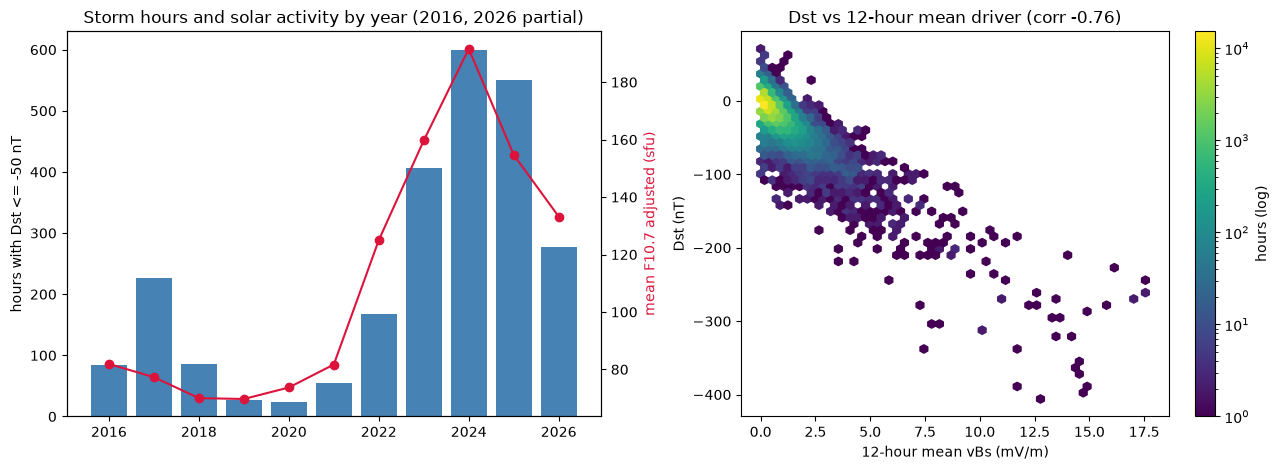

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

yrs = tab.index
ax[0].bar(yrs, tab["hrs_dst<=-50"], color="steelblue")
ax[0].set_ylabel("hours with Dst <= -50 nT")
ax[0].set_title("Storm hours and solar activity by year (2016, 2026 partial)")
ax2 = ax[0].twinx()
ax2.plot(yrs, tab["f107_mean"], color="crimson", marker="o")
ax2.set_ylabel("mean F10.7 adjusted (sfu)", color="crimson")

x = df["vbs"].rolling(12, min_periods=12).mean()
ok = x.notna() & df["dst"].notna()
r = df.loc[ok, "dst"].corr(x[ok])
hb = ax[1].hexbin(x[ok], df.loc[ok, "dst"], gridsize=50, bins="log", mincnt=1, cmap="viridis")
ax[1].set_xlabel("12-hour mean vBs (mV/m)")
ax[1].set_ylabel("Dst (nT)")
ax[1].set_title(f"Dst vs 12-hour mean driver (corr {r:.2f})")
fig.colorbar(hb, ax=ax[1], label="hours (log)")

plt.tight_layout()
plt.savefig("../reports/figures/eda_storms_and_driver.png", dpi=150, bbox_inches="tight")
plt.show()

### 02 alignment and EDA findings

- Aligned hourly table: `data/processed/aligned_hourly.parquet`, 87,024 rows (2016-07-26 00:00 to 2026-06-29 23:00 UTC), 20 columns. Built from Dst, Kp/ap (GFZ, held over each 3-hour slot), F10.7, DSCOVR magnetic field and plasma, with OMNI fill and source columns.
- Decisions applied: plasma hours with >= 75% reduced-quality minutes use OMNI hourly speed/density/temperature (decision 12); magnetometer gaps filled from OMNI hourly Bz/B (decision 14); F10.7 adjusted stored with the observed column, an interpolation flag and a spike flag (decision 7 still proposed).
- Source shares after alignment: field 86.6% DSCOVR / 13.4% OMNI / 0.0% missing; plasma 64.7% DSCOVR / 35.0% OMNI / 0.3% missing. `bx`, `by`, `bz_min` are DSCOVR-only (86.6% valid). Dst, Kp, ap, F10.7 are 100% valid.
- Delay: DSCOVR minute data shifted to Earth arrival time by 1.5e6 km / speed (speed = DSCOVR where reliable, else OMNI). Against OMNI hourly Bz: correlation 0.919 vs 0.909 for a constant 60-min delay and 0.718 with none. Better in every speed bin; most in fast wind (>600 km/s: median error 0.600 vs 0.828 nT).
- F10.7: daily values contain isolated spikes (e.g. 2024-07-30 at 412.9 with neighbours near 230-242; 2023-02-17 at 335.0 with neighbours near 160); 9 days flagged as > 1.3 x the 7-day median. Values are not altered. Cause (flare contamination) is plausible but not checked.
- Driver-response: Dst correlates -0.47 with instantaneous vBs, -0.586 at a 2-hour lag, and -0.758 with the 12-hour running mean (flat at 24 h). Hourly change in Dst responds in the same and previous hour (-0.331, -0.408 at lags 0 and 1); small positive values at lags >= 3 are consistent with recovery after a burst.
- Solar cycle: storm hours (Dst <= -50) 27 and 23 in 2019-2020, rising to 406 (2023), 600 (2024), 551 (2025), 278 (first half 2026). 2017 (226 hours at low F10.7) is an exception.
- Intense storms are concentrated: of 355 hours with Dst <= -100, 88% fall in 2023-2026 and 38% in 2024. 2019 and 2020 have none.
- Seasonality is weak and noisy over 10 years (Sep, Apr, Oct highest for Dst <= -50; no clear pattern for Dst <= -100).
- The long DSCOVR outages in 2019 to early 2020 coincide with the quietest period; the 2025 and early 2026 outages fall in active years and rely on OMNI.
- Implications: event driver features should look back at least ~12 hours before the Dst minimum; evaluation events must be chosen deliberately because intense storms are few and clustered in recent years.